# Capstone 1 • "Voice Brief → Image"

**Read the assignment text before you start.** It explains every step, the grading, and what to do if something does not work.

How to work with this notebook:
1. **File → Save a copy in Drive**, rename the copy to `Capstone1_Surname_Name` and work only in it.
2. The **"Example"** section is read-only: this is what a finished project looks like.
3. In **"Your work"**, run the cells **one by one, top to bottom** with the ▶ button. **Do not use "Run all".**
4. The fields in the cells are a form: fill them in, do not touch the code.
5. Write your answers in the text cells: double-click → type → `Shift+Enter`.

```
your voice → [Whisper] → transcript → [Gemini] → prompt → [SD-Turbo] → image
```

All three models are free and need no API keys: Whisper and SD-Turbo are open models that run inside this notebook, Gemini is built into Colab.

# Example (read-only)

This is how we did the assignment ourselves. Nothing to run here. We ran the notebook on a free Colab account. To keep the example reproducible, the voice note was made with a text-to-speech voice; you record your own voice.

### Steps 1–2. Voice → transcript
**What was said:** "I need a cover image for the menu of a small coffee shop. Morning, a cup of cappuccino with latte art on a wooden table, and a croissant next to it. Warm, soft light from the window, cozy. At the top, the words Morning Menu."

**What Whisper heard:** "I need a cover image for the menu of a small coffee shop. Morning. A cup of cappuccino with latte art on a wooden table. And a croissant next to it. Warm. Soft light from the window. Cozy. At the top. The words morning menu."

**Answer:** The words were all correct, but Whisper broke my sentences into short pieces ("Warm. Soft light…", "At the top. The words…") and wrote "morning menu" in small letters, so it no longer looked like a caption. I pasted a corrected version into `corrected_transcript`: joined "Warm, soft light" and wrote "Morning Menu" in quotes. The log showed `[STEP 2] using the corrected transcript`.

### Step 3. Prompt (style: photo, format: landscape 16:9)
> A cup of cappuccino with latte art and a croissant on a wooden table, featuring "Morning Menu" at the top. Photorealistic photo, close-up, eye-level shot, bathed in warm, soft window light, conveying a cozy morning mood.

**Answer:** Everything I asked for is there: one cup, latte art, croissant, wooden table, warm window light, cozy mood and the caption in quotes. Gemini added "close-up, eye-level shot" on its own, which I did not ask for. It also lost the purpose: the words "menu cover" are gone, so the model does not know this should be a cover with space for text.

### Steps 4–5. Image and edit
**Edit:** "show only one cup of cappuccino, keep everything else the same"

**New prompt:**
> A single cup of cappuccino, only one cup, with latte art and a croissant on a wooden table, featuring "Morning Menu" at the top. Photorealistic photo, close-up, eye-level shot, bathed in warm, soft window light, conveying a cozy morning mood.

<table><tr><td align="center"><b>Step 4</b><br>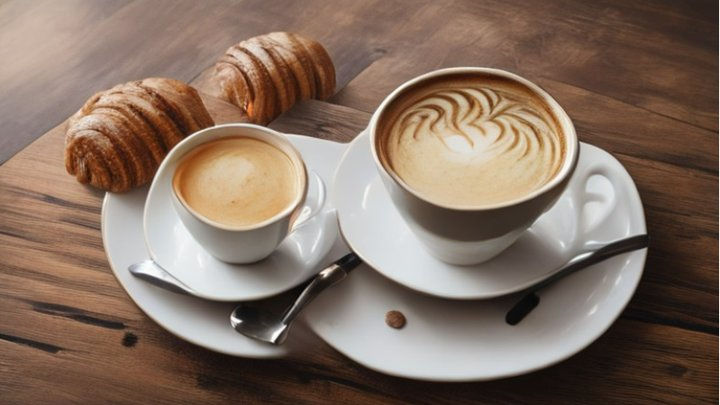</td><td align="center"><b>Step 5, after the edit</b><br>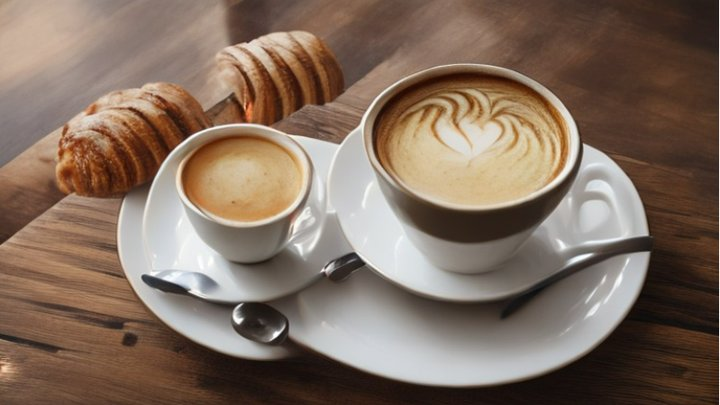</td></tr></table>

**Answer:** The edit did not work. Gemini changed the prompt correctly ("A single cup of cappuccino, only one cup"), but SD-Turbo still drew two cups. The composition stayed almost the same because the notebook keeps the same random seed; only the latte art and the croissants changed a little. Small image models are bad at counting objects, so a count edit is hard for them.

### Step 6. "As said" vs "after rewriting"
<table><tr><td align="center"><b>As said</b><br>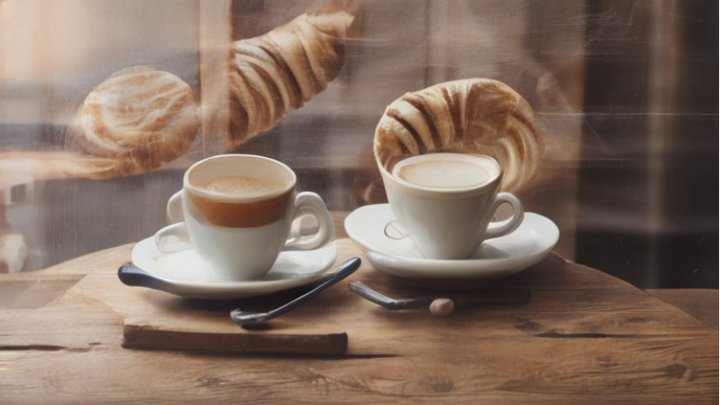</td><td align="center"><b>After rewriting</b><br>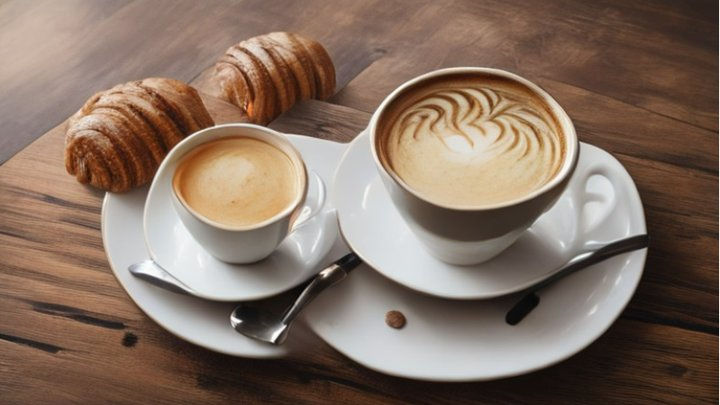</td></tr></table>

1. **Which image is closer?** The right one (after rewriting): sharp, clear table, warm light, croissants. The left one looks like a double exposure, with croissants floating in the air.

2. **What did the prompt add?** Composition ("close-up, eye-level"), a clear style ("photorealistic photo") and the light description. Without them the model mixed the scene: you can see that in the blurry left image.

3. **What went wrong in both?** Two cups instead of one, and no "Morning Menu" caption at all.

### Step 7. Conclusions
Most mistakes happened at the image step: SD-Turbo ignored the number of cups and never drew the "Morning Menu" caption, even when the prompt asked for it clearly. Whisper heard every word but changed the punctuation, so I fixed the transcript by hand before Gemini used it. Gemini wrote a good prompt but added a camera angle I had not asked for and dropped the words "menu cover". Next time I would say "menu cover with empty space at the top for text" in my brief and leave the caption for a designer, because this model cannot write text.

# Your work

Run the cells one by one, top to bottom.

## Step 0. Setup (2–5 minutes, once)
Press ▶ and wait for the line that starts with `DONE`.

In [ ]:
# @title ▶ Run: setup
import subprocess, sys, os, time, base64, io, random, textwrap, concurrent.futures as _cf
os.environ.update(HF_HUB_VERBOSITY="error", TRANSFORMERS_VERBOSITY="error", HF_HUB_DISABLE_PROGRESS_BARS="1",
                  TRANSFORMERS_NO_ADVISORY_WARNINGS="1")
print("Installing and downloading models. This takes 2-5 minutes...")
subprocess.run([sys.executable, "-m", "pip", "-q", "install", "openai-whisper"], check=True,
               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("diffusers", "transformers", "huggingface_hub"):
    logging.getLogger(_n).setLevel(logging.ERROR)
import torch, whisper
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as _dlog
from transformers.utils import logging as _tlog
_dlog.set_verbosity_error(); _dlog.disable_progress_bar(); _tlog.set_verbosity_error()
from IPython.display import display, Audio, HTML, Image
from google.colab import ai, files
from google.colab.output import eval_js

class StopCell(Exception):
    pass
get_ipython().set_custom_exc((StopCell,), lambda *a, **k: None)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
STYLE_EN = {"photo": "photorealistic photo", "watercolor": "watercolor illustration", "3D": "3D render",
            "flat illustration": "flat vector illustration", "anime": "anime illustration"}
FMT = {"square": (512, 512, "square 1:1"), "landscape 16:9": (768, 432, "landscape 16:9"),
       "portrait 9:16": (432, 768, "portrait 9:16")}
GEMINI_MODELS = ["google/gemini-2.5-flash", "google/gemini-2.5-flash-lite"]
SEED = random.randint(1, 999999)
S = {}
_ex = _cf.ThreadPoolExecutor(8)

def say(text):
    print(textwrap.fill(text, 100))

def log(n, text):
    print(f"[STEP {n}] {text}")

def need(*keys_steps):
    for key, n in keys_steps:
        if key not in S:
            print(f"Run step {n} first."); raise StopCell

def ask_gemini(prompt):
    """Gemini built into Colab, no key. Explicit model + timeout: without them a call can hang."""
    for m in GEMINI_MODELS:
        t = time.time()
        f = _ex.submit(ai.generate_text, prompt, model_name=m)
        try:
            out = f.result(timeout=60).strip().strip("`").strip().strip('"*').strip()
            return out, m, time.time() - t
        except Exception:
            continue
    print("Gemini error. Wait 1 minute and run the cell again. If it fails 3 times, "
          "use the prompt fallback (section 10 of the assignment).")
    raise StopCell

def make_image(prompt, w, h):
    t = time.time()
    g = torch.Generator(DEVICE).manual_seed(SEED)
    img = PIPE(prompt, num_inference_steps=1, guidance_scale=0.0, width=w, height=h, generator=g).images[0]
    buf = io.BytesIO(); img.save(buf, format="JPEG", quality=90)
    return buf.getvalue(), time.time() - t

def upload_one():
    print('Press "Choose Files" and pick your file.')
    up = files.upload()
    if not up:
        print("No file selected. Run the cell again."); raise StopCell
    return next(iter(up.items()))

def to_jpeg(data):
    from PIL import Image as _P
    buf = io.BytesIO(); _P.open(io.BytesIO(data)).convert("RGB").save(buf, format="JPEG", quality=90)
    return buf.getvalue()

def get_image(n, prompt, w, h, source):
    if source == "upload manually":
        name, data = upload_one()
        log(n, "image: uploaded manually")
        return to_jpeg(data)
    try:
        data, secs = make_image(prompt, w, h)
    except Exception as e:
        print(f"Error: image not created ({type(e).__name__}). Run the cell again. If it fails 3 times, "
              "use the image fallback (section 10 of the assignment).")
        raise StopCell
    log(n, f"image: model sd-turbo, {secs:.1f} s")
    return data

def show_img(data, width=420):
    display(Image(data=data, width=width))

def row(items, width=380):
    cells = "".join(f'<td style="vertical-align:top;padding:6px;text-align:center"><b>{c}</b><br>'
                    f'<img src="data:image/jpeg;base64,{base64.b64encode(d).decode()}" style="width:{width}px"></td>'
                    for c, d in items)
    display(HTML(f"<table><tr>{cells}</tr></table>"))

REC_JS = """
async function rec(){
  let stream;
  try { stream = await navigator.mediaDevices.getUserMedia({audio:true}); }
  catch(e) { return "ERR"; }
  const box=document.createElement('div');
  const btn=document.createElement('button');
  btn.textContent='● Record'; btn.style='font-size:18px;padding:8px 18px;cursor:pointer';
  const info=document.createElement('span'); info.style='margin-left:12px;font-size:15px';
  box.appendChild(btn); box.appendChild(info); document.body.appendChild(box);
  await new Promise(r=>btn.onclick=r);
  const chunks=[]; const mr=new MediaRecorder(stream);
  mr.ondataavailable=e=>chunks.push(e.data);
  mr.start(); btn.textContent='■ Stop'; info.textContent='Recording... press Stop when you are done.';
  await new Promise(r=>btn.onclick=r);
  const done=new Promise(r=>mr.onstop=r); mr.stop(); await done;
  stream.getTracks().forEach(t=>t.stop());
  btn.disabled=true; info.textContent='Recording saved.';
  const b=new Uint8Array(await new Blob(chunks).arrayBuffer());
  let s=''; for(let i=0;i<b.length;i+=8192){ s+=String.fromCharCode.apply(null,b.subarray(i,i+8192)); }
  return btoa(s);
}
rec();
"""

WHISPER = whisper.load_model("small", device=DEVICE)
PIPE = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo", variant="fp16",
    torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32).to(DEVICE)
PIPE.set_progress_bar_config(disable=True)
print("DONE. Go to step 1. (Each image will take 1-2 minutes to draw.)" if DEVICE == "cpu" else "DONE. Go to step 1.")

## Step 1. Voice
Choose the `method` in the form and press ▶. Then listen to the recording.

In [ ]:
# @title ▶ Run: voice
if "S" not in globals():
    raise RuntimeError("Run step 0 first.")
method = "Record here"  # @param ["Record here", "Upload a file"]
import whisper.audio as _wa
if method == "Record here":
    b64 = eval_js(REC_JS, timeout_sec=900)
    if not b64 or b64 == "ERR":
        print('The microphone did not turn on. If Colab showed a permissions window, press "Accept" and run '
              'the cell again. If there was no window or it did not help, choose "Upload a file".')
        raise StopCell
    path = "voice.webm"
    open(path, "wb").write(base64.b64decode(b64))
else:
    name, data = upload_one()
    path = "voice_" + name.replace(" ", "_")
    open(path, "wb").write(data)
try:
    secs = len(_wa.load_audio(path)) / 16000
except Exception:
    print("Could not read this file. Use mp3, m4a, wav or ogg and run the cell again."); raise StopCell
S.clear(); S["audio"] = path
log(1, f"recording: {secs:.0f} s")
display(Audio(path))
print("Listen to the recording. If you hear nothing, record again.")

## Step 2. Voice → text (Whisper)
Press ▶. If the transcript has mistakes, copy it into the `corrected_transcript` field, fix it and press ▶ again.

In [ ]:
# @title ▶ Run: voice → text
if "S" not in globals():
    raise RuntimeError("Run step 0 first.")
corrected_transcript = ""  # @param {type:"string"}
need(("audio", 1))
if S.get("whisper_for") != S["audio"]:
    t = time.time()
    S["whisper"] = WHISPER.transcribe(S["audio"], fp16=(DEVICE == "cuda"))["text"].strip()
    S["whisper_for"] = S["audio"]
    S["whisper_log"] = f"transcript: model whisper-small, {time.time() - t:.1f} s"
log(2, S["whisper_log"])
print("Transcript (what Whisper heard):"); print(S["whisper"]); print()
new = corrected_transcript.strip() or S["whisper"]
if S.get("transcript") != new:
    for k in ("prompt", "img4", "prompt5", "prompt5_for", "img5", "img6"):
        S.pop(k, None)
S["transcript"] = new
if corrected_transcript.strip():
    log(2, "using the corrected transcript")
    print("Text that goes further:"); print(S["transcript"])

**Were there mistakes in the transcript? Which ones?**

Your answer: 

## Step 3. Text → prompt (Gemini)
Choose the `style` and `image_format`. Leave `manual_prompt` empty (it is only for the fallback). Press ▶.

In [ ]:
# @title ▶ Run: text → prompt
if "S" not in globals():
    raise RuntimeError("Run step 0 first.")
style = "photo"  # @param ["photo", "watercolor", "3D", "flat illustration", "anime"]
image_format = "square"  # @param ["square", "landscape 16:9", "portrait 9:16"]
manual_prompt = ""  # @param {type:"string"}
need(("transcript", 2))
S["style"], S["fmt"] = STYLE_EN[style], FMT[image_format]
if manual_prompt.strip():
    S["prompt"] = manual_prompt.strip(); log(3, "prompt: entered manually")
else:
    req = ("You are a prompt engineer for an image generation model. Rewrite the client's brief below into ONE "
           "English image prompt: a single paragraph of 30-50 words (the image model reads only "
           "the first ~75 words), covering, in this order: subject, key details, style, composition and camera "
           "angle, lighting, mood. "
           f"The style must be: {S['style']}. The format is {S['fmt'][2]}. "
           "If the brief asks for text on the image, keep that text exactly and put it in double quotes. "
           "Do not add objects or ideas the client did not ask for. Output only the prompt, nothing else.\n\n"
           "Client brief: " + S["transcript"])
    out, model, secs = ask_gemini(req)
    S["prompt"] = out; log(3, f"prompt: model {model}, {secs:.1f} s")
S.pop("img4", None)
print("Image prompt:"); say(S["prompt"])

**Does the prompt contain everything you asked for? Does it contain anything you did not ask for?**

Your answer: 

## Step 4. Prompt → image (SD-Turbo)
Leave `source` as "SD-Turbo in Colab". Press ▶.

In [ ]:
# @title ▶ Run: prompt → image
if "S" not in globals():
    raise RuntimeError("Run step 0 first.")
source = "SD-Turbo in Colab"  # @param ["SD-Turbo in Colab", "upload manually"]
need(("prompt", 3))
w, h, _ = S["fmt"]
S["img4"] = get_image(4, S["prompt"], w, h, source)
show_img(S["img4"])

## Step 5. Edit in words
Write one edit in the `edit` field using the pattern "change only X, keep everything else the same". Leave `source` and `manual_prompt` as they are. Press ▶.

In [ ]:
# @title ▶ Run: edit
if "S" not in globals():
    raise RuntimeError("Run step 0 first.")
edit = ""  # @param {type:"string"}
source = "SD-Turbo in Colab"  # @param ["SD-Turbo in Colab", "upload manually"]
manual_prompt = ""  # @param {type:"string"}
need(("img4", 4))
if not edit.strip():
    print('Fill in the "edit" field and run the cell again.'); raise StopCell
key = (edit.strip(), S["prompt"])
if manual_prompt.strip():
    S["prompt5"] = manual_prompt.strip(); S.pop("prompt5_for", None); log(5, "prompt: entered manually")
elif S.get("prompt5_for") == key:
    log(5, "prompt: same edit as the previous run, prompt reused")
else:
    req = ("Here is an image prompt:\n" + S["prompt"] + "\n\nThe client asks for this change: " + edit.strip()
           + "\nRewrite the prompt so that the change is impossible to miss: state it explicitly in the FIRST "
           "sentence (for example, if the change is 'make the sky purple', the first sentence must say the sky is "
           "purple), and remove any words that contradict it. Keep everything else the same. "
           "Output only the new prompt.")
    out, model, secs = ask_gemini(req)
    S["prompt5"] = out; S["prompt5_for"] = key; log(5, f"prompt: model {model}, {secs:.1f} s")
if S["prompt5"].strip() == S["prompt"].strip():
    print("Note: the prompt did not change, so the image will be the same. "
          "Write your edit more concretely and run the cell again.")
print("New prompt after the edit:"); say(S["prompt5"]); print()
w, h, _ = S["fmt"]
S["img5"] = get_image(5, S["prompt5"], w, h, source)
row([("Before the edit (step 4)", S["img4"]), ("After the edit (step 5)", S["img5"])])

**Did the edit work? What else changed that you did not ask for?**

Your answer: 

## Step 6. "As said" vs "after rewriting"
Leave `source` as "SD-Turbo in Colab". Press ▶.

In [ ]:
# @title ▶ Run: comparison
if "S" not in globals():
    raise RuntimeError("Run step 0 first.")
source = "SD-Turbo in Colab"  # @param ["SD-Turbo in Colab", "upload manually"]
need(("img4", 4))
w, h, _ = S["fmt"]
S["img6"] = left = get_image(6, S["transcript"], w, h, source)
row([("As said (raw transcript)", left), ("After rewriting (step 4 image)", S["img4"])])

1. **Which image is closer to what you wanted?**

   Your answer: 

2. **What exactly did the step 3 prompt add (light, composition, style, details)?**

   Your answer: 

3. **What did the model get wrong in both images?**

   Your answer: 

## Step 7. Final conclusions
4–6 sentences with concrete examples from your work: at which step were there the most mistakes and why; what you fixed by hand; what you would do differently next time. If you used a fallback, say so.

Your answer: 

# Bonus (optional, pick one)

## Bonus A. Another service
Make an image from the step 3 prompt at gemini.google.com, download it, press ▶ below and pick the file.

In [ ]:
# @title ▶ Run: upload an image
if "S" not in globals():
    raise RuntimeError("Run step 0 first.")
name, data = upload_one()
print("Your image from another service:")
show_img(to_jpeg(data))

**Which service did better and why?**

Your answer: 

## Bonus B. Series
Write three scenes (3–8 words each) in `scene_1`, `scene_2`, `scene_3` and press ▶.

In [ ]:
# @title ▶ Run: series
if "S" not in globals():
    raise RuntimeError("Run step 0 first.")
scene_1 = ""  # @param {type:"string"}
scene_2 = ""  # @param {type:"string"}
scene_3 = ""  # @param {type:"string"}
need(("prompt", 3))
scenes = [scene_1.strip(), scene_2.strip(), scene_3.strip()]
if not all(scenes):
    print("Fill in all three scene fields and run the cell again."); raise StopCell
req = ("From this image prompt, write ONLY a short English description (15-30 words) of the main character or "
       "object: appearance, colours, clothing or materials. No background, no action. Output only the description."
       "\n\n" + S["prompt"])
subj, model, secs = ask_gemini(req)
log("B", "hero description for the series: " + subj)
w, h, _ = S["fmt"]
imgs = []
for sc in scenes:
    try:
        d, secs = make_image(f"{sc}. {subj} {S['style']}.", w, h)
    except Exception as e:
        print(f"Error: image not created ({type(e).__name__}). Run the cell again."); raise StopCell
    imgs.append((sc, d))
log("B", f"3 images: model sd-turbo")
row(imgs, width=260)

**Is the hero recognisable in all three images? What drifted?**

Your answer: 